# In-spec check: unfittable samples (LogNSW run)

The LogNSW model cannot fit a small set of extreme-slope samples even in-sample
(train split). This notebook checks whether the **inputs** of those outlier samples
are "in spec": for each per-sample input descriptor, the distribution of the
well-fitted samples of the same design_version defines the reference range, and each
outlier is tested against it. If the outliers are in-spec everywhere, the information
driving their extreme slopes is not in the features.

- Outliers: top-20 worst-fitted **train** samples of the LogNSW run (fold 3 cache).
- Reference: same-design samples with error below the median.
- Data: `data/input/dyconex_260701_seq2slope/train_data.npz`.

In [12]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent  # allow running from notebooks/

DATA_DIR = ROOT / "data" / "input" / "dyconex_260701_seq2slope"
RUN_DIR = (ROOT / "experiments" / "training" / "results"
           / "proTEncSlope_LogNSW_dyconex_2000ep_11117122")
FOLD = 3      # fold of the cached train predictions
SHIFT = 1e-3  # loss_log_shift of the lognormal loss
TOP_N = 20    # number of worst-fitted samples to inspect

# input feature channels (meta_seq/feature_map.json)
CH = {"group": 0, "process": 1, "occurrence": 2, "step": 3, "variable": 4,
      "value": 5, "order": 6, "year": 7, "month": 8, "day": 9, "hour": 10,
      "minute": 11, "design": 12, "panel_position": 13}

train = np.load(DATA_DIR / "train_data.npz")
x_all, y_all = train["x"], train["y"]  # y: (B, 2, 4) = [sample_id, variable, slope, intercept]

cache = np.load(RUN_DIR / "predictions_cache_train.npz", allow_pickle=True)

# map cache rows to dataset rows via the sample id (y channel 0); the fold indices
# are dataloader order, not cache order, so the sample id is the robust key
sid_all = y_all[:, 0, 0].astype(int)
assert len(np.unique(sid_all)) == len(sid_all), "sample ids not unique"
pos = {s: i for i, s in enumerate(sid_all)}
ds_idx = np.array([pos[s] for s in cache["targets"][:, 0, 0].astype(int)])
assert np.allclose(x_all[ds_idx], cache["inputs"], equal_nan=True), "cache/dataset mismatch"

with open(DATA_DIR / "meta_seq" / "design_version_map.json") as f:
    design_name = {v: k for k, v in json.load(f).items()}
with open(DATA_DIR / "meta_seq" / "process_map.json") as f:
    process_name = {v: k for k, v in json.load(f).items()}
metrics_df = pd.read_parquet(DATA_DIR / "meta_seq" / "sample_metrics.parquet")

print(f"train data: x={x_all.shape}, y={y_all.shape}")
print(f"fold {FOLD} train cache: {cache['outputs'].shape}")

train data: x=(1311, 557, 14), y=(1311, 2, 4)
fold 3 train cache: (1049, 2, 2)


## 1. Errors and outlier selection

Same y-space transform as in the eval notebook: `y_pred = exp(mu) - shift` (median of
the log-normal). Per-sample error = max |err| over SenseA/SenseB.

In [13]:
mu_y = np.exp(cache["outputs"][..., 0]) - SHIFT
y_true = cache["targets"][:, :2, 3]
err = np.abs(mu_y - y_true).max(axis=1)

def first_nz(row):
    nz = row[row > 0]
    return int(nz[0]) if len(nz) else 0

design_all = np.array([first_nz(r) for r in x_all[:, :, CH["design"]]])
design = design_all[ds_idx]

err_med = np.median(err)
outlier_pos = np.argsort(err)[::-1][:TOP_N]  # positions within the cache/fold split

print(f"fold train samples: {len(err)}, median err = {err_med:.4g}")
print(f"outlier err range : [{err[outlier_pos].min():.4g}, {err[outlier_pos].max():.4g}]")
print("outlier design counts:",
      {design_name[d]: int((design[outlier_pos] == d).sum()) for d in np.unique(design[outlier_pos])})

fold train samples: 1049, median err = 0.0004958
outlier err range : [0.004091, 0.05953]
outlier design counts: {'426816_C': 1, '436425_J': 7, '453828_B': 12}


## 2. Per-sample input descriptors

Numeric descriptors per sample: sequence length, categorical coverage (number of
distinct processes/steps/variables/occurrences), panel position, value_norm stats
(min/max/mean/last/range), duration of the process chain, plus the pre-computed
rarity scores from `sample_metrics.parquet` (joined on the group id).

In [14]:
def descriptors(x_row):
    """Per-sample input descriptors from one (L, 14) input matrix."""
    m = x_row[:, CH["process"]] > 0  # non-padding tokens
    v_raw = x_row[m, CH["value"]]
    valid = ~np.isnan(v_raw)
    v = v_raw[valid]
    ord_v = x_row[m, CH["order"]][valid]  # order of the non-NaN value tokens
    t = x_row[m, :][:, [CH["year"], CH["month"], CH["day"], CH["hour"], CH["minute"]]]
    t_abs = (((t[:, 0] * 12 + t[:, 1]) * 31 + t[:, 2]) * 24 + t[:, 3]) * 60 + t[:, 4]
    return {
        "group": int(x_row[m, CH["group"]][0]),
        "seq_len": int(m.sum()),
        "n_processes": len(np.unique(x_row[m, CH["process"]])),
        "n_steps": len(np.unique(x_row[m, CH["step"]])),
        "n_variables": len(np.unique(x_row[m, CH["variable"]])),
        "n_occurrences": len(np.unique(x_row[m, CH["occurrence"]])),
        "panel_position": first_nz(x_row[:, CH["panel_position"]]),
        "val_min": float(np.min(v)),
        "val_max": float(np.max(v)),
        "val_mean": float(np.mean(v)),
        "val_last": float(v[np.argmax(ord_v)]),
        "val_ptp": float(np.ptp(v)),
        "duration_min": float(t_abs.max() - t_abs.min()),
    }

desc = pd.DataFrame([descriptors(x_all[i]) for i in ds_idx])
desc["design"] = design
desc["err"] = err
desc["outlier"] = False
desc.loc[outlier_pos, "outlier"] = True
desc["sample_id"] = y_all[ds_idx, 0, 0].astype(int)
desc["slope_max"] = np.abs(y_true).max(axis=1)
desc = desc.merge(metrics_df[["group", "rarity_last_value",
                               "rarity_nan_fraction_input"]], on="group", how="left")
desc.head()

,group,seq_len,n_processes,n_steps,n_variables,n_occurrences,panel_position,val_min,val_max,val_mean,val_last,val_ptp,duration_min,design,err,outlier,sample_id,slope_max,rarity_last_value,rarity_nan_fraction_input
0,320,402,7,5,272,4,1,0.0,1.0,0.452676,0.856303,1.0,75440.0,5,0.000464,False,320,0.004651,0.087890,0.000000
1,436,557,7,5,320,4,1,0.0,1.0,0.400809,0.856370,1.0,104607.0,5,0.000150,False,436,0.003674,0.009299,0.000000
2,740,245,6,5,170,4,1,0.0,1.0,0.500168,0.856328,1.0,97203.0,5,0.000219,False,740,0.002269,0.008900,0.000000
3,91,504,7,5,320,4,1,0.0,1.0,0.416488,0.007909,1.0,93930.0,5,0.000160,False,91,0.002653,0.003751,0.000000
4,140,428,7,5,274,4,1,0.0,1.0,0.447031,0.856514,1.0,59982.0,5,0.000628,False,140,0.003813,0.027997,0.109706


## 3. In-spec table

For each descriptor and design_version, the reference range is computed from the
well-fitted samples (error below median). Flags: `.` = inside [q01, q99],
`o` = inside [min, max] but outside [q01, q99], `OUT` = outside [min, max].

In [15]:
NUM_COLS = ["seq_len", "n_processes", "n_steps", "n_variables", "n_occurrences",
            "panel_position", "val_min", "val_max", "val_mean", "val_last",
            "val_ptp", "duration_min", "rarity_last_value", "rarity_nan_fraction_input"]

flag_mat = pd.DataFrame(index=[int(s) for s in desc.loc[outlier_pos, "sample_id"]],
                        columns=NUM_COLS, data=".")
out_rows = []
for pos in outlier_pos:
    r = desc.loc[pos]
    ref = desc[(desc["design"] == r["design"]) & (~desc["outlier"]) & (desc["err"] < err_med)]
    sid = int(r["sample_id"])
    for col in NUM_COLS:
        lo, hi = ref[col].min(), ref[col].max()
        q1, q99 = ref[col].quantile(0.01), ref[col].quantile(0.99)
        val = r[col]
        if not (lo <= val <= hi):
            flag_mat.loc[sid, col] = "OUT"
            out_rows.append({"sample_id": sid, "design": design_name[r["design"]],
                             "descriptor": col, "value": val,
                             "ref_min": lo, "ref_max": hi, "n_ref": len(ref)})
        elif not (q1 <= val <= q99):
            flag_mat.loc[sid, col] = "o"

n_out = (flag_mat == "OUT").sum(axis=1)
n_edge = (flag_mat == "o").sum(axis=1)
print(f"outliers fully inside [min,max] everywhere: {(n_out == 0).sum()}/{TOP_N}")
print(f"outliers fully inside [q01,q99] everywhere: {((n_out + n_edge) == 0).sum()}/{TOP_N}")
flag_mat

outliers fully inside [min,max] everywhere: 9/20
outliers fully inside [q01,q99] everywhere: 6/20


,seq_len,n_processes,n_steps,n_variables,n_occurrences,panel_position,val_min,val_max,val_mean,val_last,val_ptp,duration_min,rarity_last_value,rarity_nan_fraction_input
1036,.,.,.,.,.,.,.,.,.,.,.,.,o,.
1039,.,.,.,.,.,.,.,.,.,.,.,.,.,.
1043,.,.,.,.,.,.,.,.,.,.,.,.,o,.
337,.,.,.,.,.,.,.,.,OUT,.,.,.,.,.
542,.,.,.,.,.,.,.,.,.,.,.,.,.,.
919,.,.,.,.,.,.,.,.,.,.,.,.,OUT,.
471,.,.,.,.,.,.,.,.,.,.,.,.,OUT,.
1103,.,.,.,.,.,.,.,.,.,.,.,.,.,.
893,.,.,.,.,.,.,.,.,.,.,.,.,.,.
884,.,.,.,.,.,.,.,.,.,.,.,.,.,.


In [16]:
# out-of-spec entries (outside the reference [min, max] of the same design)
df_out = pd.DataFrame(out_rows)
if len(df_out):
    display(df_out.sort_values(["descriptor", "sample_id"]).reset_index(drop=True))
else:
    print("All outliers are inside the reference [min, max] for every descriptor.")

,sample_id,design,descriptor,value,ref_min,ref_max,n_ref
0,192,453828_B,rarity_last_value,0.660194,0.00000,0.207120,290
1,197,453828_B,rarity_last_value,0.320388,0.00000,0.207120,290
2,471,453828_B,rarity_last_value,0.320388,0.00000,0.207120,290
3,891,453828_B,rarity_last_value,0.271845,0.00000,0.207120,290
4,917,436425_J,rarity_last_value,0.116505,0.00000,0.058999,151
5,918,436425_J,rarity_last_value,0.087890,0.00000,0.058999,151
6,919,436425_J,rarity_last_value,0.207120,0.00000,0.058999,151
7,920,436425_J,rarity_last_value,0.137416,0.00000,0.058999,151
8,1061,453828_B,rarity_last_value,0.320388,0.00000,0.207120,290
9,1363,426816_C,rarity_last_value,0.320388,0.00000,0.165931,29


## 4. Categorical coverage

Set-inclusion check: are the processes / steps / variables present in an outlier's
input also present in at least one well-fitted reference sample of the same design?

In [17]:
def cat_sets(x_row):
    m = x_row[:, CH["process"]] > 0
    return {k: set(np.unique(x_row[m, CH[k]]).astype(int))
            for k in ("process", "step", "variable")}

sets_all = {pos: cat_sets(x_all[ds_idx[pos]]) for pos in range(len(ds_idx))}

for pos in outlier_pos:
    r = desc.loc[pos]
    ref_pos = desc.index[(desc["design"] == r["design"]) & (~desc["outlier"])
                         & (desc["err"] < err_med)]
    for k in ("process", "step", "variable"):
        ref_union = set().union(*(sets_all[p][k] for p in ref_pos))
        unseen = sets_all[pos][k] - ref_union
        if unseen:
            names = [process_name.get(v, str(v)) for v in unseen] if k == "process" else unseen
            print(f"sample {int(r['sample_id'])} (design {design_name[r['design']]}): "
                  f"unseen {k}(s) {names}")
print("(no lines above = every outlier's categories are covered by the reference)")

(no lines above = every outlier's categories are covered by the reference)


## 5. Distribution plots for out-of-spec / edge descriptors

One panel per descriptor where at least one outlier falls outside the reference
[q01, q99]. Gray dots = well-fitted reference samples of the same design, red crosses
= outliers. If no descriptor qualifies, the slope error itself is shown for context.

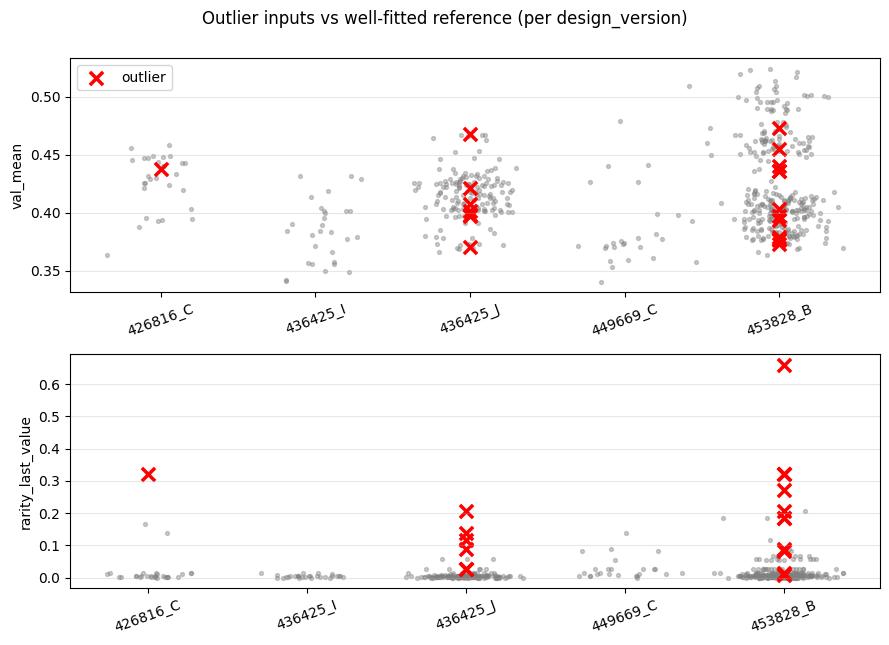

In [18]:
cols_to_plot = [c for c in NUM_COLS if (flag_mat[c] != ".").any()]
if not cols_to_plot:
    cols_to_plot = ["val_max"]  # fallback: show something
    print("All outliers in spec on every descriptor; showing val_max for context.")

rng = np.random.default_rng(0)
fig, axes = plt.subplots(len(cols_to_plot), 1,
                         figsize=(9, 3.2 * len(cols_to_plot)), squeeze=False)
for ax, col in zip(axes[:, 0], cols_to_plot):
    for j, d in enumerate(sorted(desc["design"].unique())):
        sub = desc[desc["design"] == d]
        ref = sub[~sub["outlier"] & (sub["err"] < err_med)][col]
        out = sub[sub["outlier"]][col]
        xj = j + 0.15 * rng.standard_normal(len(ref))
        ax.scatter(xj, ref, s=8, color="gray", alpha=0.4)
        ax.scatter([j] * len(out), out, s=90, marker="x", color="red", lw=2.5,
                   label="outlier" if j == 0 else None)
    ax.set_xticks(range(len(sorted(desc['design'].unique()))))
    ax.set_xticklabels([design_name[d] for d in sorted(desc["design"].unique())],
                       rotation=20)
    ax.set_ylabel(col)
    ax.grid(True, alpha=0.3, axis="y")
axes[0, 0].legend()
fig.suptitle("Outlier inputs vs well-fitted reference (per design_version)", y=1.0)
fig.tight_layout()
plt.show()

## 6. Chain structure

The aggregate descriptors above pool over the whole process chain. From here on the
chains are compared directly. Each sample's chain = ordered sequence of distinct
consecutive `(process, occurrence, step)` triples. For each outlier: does the exact
chain occur
among the well-fitted reference samples of the same design, and what is the minimum
Levenshtein distance to any reference chain (calibrated against reference-to-
reference distances)?

In [19]:
# token-level table: one row per non-padding token of each fold-train sample
def token_table(pos):
    x_row = x_all[ds_idx[pos]]
    m = x_row[:, CH["process"]] > 0
    t = x_row[m, :][:, [CH["year"], CH["month"], CH["day"], CH["hour"], CH["minute"]]]
    t_abs = (((t[:, 0] * 12 + t[:, 1]) * 31 + t[:, 2]) * 24 + t[:, 3]) * 60 + t[:, 4]
    return pd.DataFrame({
        "pos": pos,
        "process": x_row[m, CH["process"]].astype(int),
        "occurrence": x_row[m, CH["occurrence"]].astype(int),
        "step": x_row[m, CH["step"]].astype(int),
        "variable": x_row[m, CH["variable"]].astype(int),
        "value": x_row[m, CH["value"]],
        "order": x_row[m, CH["order"]].astype(int),
        "t_abs": t_abs,
    })

tok = pd.concat([token_table(p) for p in range(len(ds_idx))], ignore_index=True)
tok["design"] = tok["pos"].map(desc["design"])
ref_mask = (~desc["outlier"]) & (desc["err"] < err_med)  # well-fitted reference
tok["ref"] = tok["pos"].map(ref_mask)
# position key: (design, process, step, variable)
tok["pkey"] = list(zip(tok["design"], tok["process"], tok["step"], tok["variable"]))

with open(DATA_DIR / "meta_seq" / "variable_map_input.json") as f:
    var_name = {v: k for k, v in json.load(f).items()}

def chain_of(g):
    """Ordered sequence of distinct consecutive (process, occurrence, step) triples."""
    g = g.sort_values("order")
    out = []
    for p in zip(g["process"], g["occurrence"], g["step"]):
        if not out or p != out[-1]:
            out.append(p)
    return tuple(out)

def lev(a, b):
    """Levenshtein distance between two tuples."""
    dp = list(range(len(b) + 1))
    for i in range(1, len(a) + 1):
        prev, dp[0] = dp[0], i
        for j in range(1, len(b) + 1):
            prev, dp[j] = dp[j], min(dp[j] + 1, dp[j - 1] + 1,
                                     dp[j - 1] + (a[i - 1] != b[j - 1]))
    return dp[len(b)]

chains = {p: chain_of(g) for p, g in tok.groupby("pos")}

rows = []
for pos in outlier_pos:
    d = desc.loc[pos, "design"]
    ref_chains = [chains[p] for p in desc.index[(desc["design"] == d) & ref_mask]]
    rows.append({"sample_id": int(desc.loc[pos, "sample_id"]),
                 "design": design_name[d],
                 "chain_len": len(chains[pos]),
                 "exact_match_in_ref": chains[pos] in ref_chains,
                 "min_edit_dist": min(lev(chains[pos], rc) for rc in ref_chains)})
df_chain = pd.DataFrame(rows)

# calibration: reference-to-reference min edit distance per design
print("reference-to-reference min edit distance per design (min/median/max):")
for d in sorted(desc["design"].unique()):
    rc = [chains[p] for p in desc.index[(desc["design"] == d) & ref_mask]]
    if len(rc) > 1:
        dm = [min(lev(a, b) for j, b in enumerate(rc) if j != i)
              for i, a in enumerate(rc)]
        print(f"  {design_name[d]}: {int(np.min(dm))}/{int(np.median(dm))}/{int(np.max(dm))} "
              f"(n={len(rc)})")
df_chain

reference-to-reference min edit distance per design (min/median/max):
  426816_C: 21/25/27 (n=29)
  436425_I: 22/26/29 (n=29)
  436425_J: 24/30/35 (n=151)
  449669_C: 22/28/29 (n=25)
  453828_B: 16/30/34 (n=290)


,sample_id,design,chain_len,exact_match_in_ref,min_edit_dist
0,1036,453828_B,33,False,33
1,1039,453828_B,33,False,33
2,1043,453828_B,33,False,33
3,337,436425_J,28,False,29
4,542,453828_B,30,True,30
5,919,436425_J,27,False,29
6,471,453828_B,30,False,31
7,1103,436425_J,31,True,31
8,893,453828_B,26,False,27
9,884,436425_J,26,True,26


## 7. Per-position value check

Per token `(process, step, variable)`, the outlier's `value_norm` is tested against
the reference distribution of the *same position* (same design). A token is OUT if
its value lies outside the reference [min, max] (positions with fewer than
`MIN_REF` reference values are skipped).

In [20]:
MIN_REF = 10  # minimum reference values for a position to be checkable

# pkey -> (min, max, n) over the well-fitted reference samples
ref_stats = {k: (g.min(), g.max(), len(g))
             for k, g in tok[tok["ref"] & tok["value"].notna()].groupby("pkey")["value"]}

rows, summ = [], []
for pos in outlier_pos:
    g = tok[(tok["pos"] == pos) & tok["value"].notna()]
    n_chk = n_out = 0
    for _, r in g.iterrows():
        if r["pkey"] not in ref_stats:
            continue
        lo, hi, n_ref = ref_stats[r["pkey"]]
        if n_ref < MIN_REF:
            continue
        n_chk += 1
        if not (lo <= r["value"] <= hi):
            n_out += 1
            rows.append({"sample_id": int(desc.loc[pos, "sample_id"]),
                         "design": design_name[desc.loc[pos, "design"]],
                         "process": process_name.get(r["process"], r["process"]),
                         "step": r["step"],
                         "variable": var_name.get(r["variable"], r["variable"]),
                         "value": round(r["value"], 4),
                         "ref_min": round(lo, 4),
                         "ref_max": round(hi, 4),
                         "n_ref": n_ref})
    summ.append({"sample_id": int(desc.loc[pos, "sample_id"]),
                 "tokens_checked": n_chk, "tokens_out": n_out})

df_posval = pd.DataFrame(rows)
display(pd.DataFrame(summ).set_index("sample_id"))
if len(df_posval):
    display(df_posval)
else:
    print("No out-of-spec token values in any outlier.")

,tokens_checked,tokens_out
sample_id,,
1036,533,0
1039,533,1
1043,533,0
337,204,0
542,458,0
919,399,16
471,421,0
1103,380,0
893,404,2


,sample_id,design,process,step,variable,value,ref_min,ref_max,n_ref
0,1039,453828_B,galvanic_anna,1,gal_anna_174,0.1277,0.1277,0.1277,387
1,919,436425_J,plasma_spongebob,1,pla_sb_14@workstatus1,0.4832,0.4979,0.5551,58
2,919,436425_J,plasma_spongebob,1,pla_sb_14@workstatus2,0.6703,0.6718,0.6934,58
3,919,436425_J,plasma_spongebob,1,pla_sb_15@workstatus12,0.8681,0.5350,0.8647,58
4,919,436425_J,plasma_spongebob,1,pla_sb_20@workstatus1,0.4000,0.3278,0.3972,58
...,...,...,...,...,...,...,...,...,...
73,918,436425_J,multibond,1,mul_38,0.8369,0.3506,0.8109,268
74,918,436425_J,microetch,1,mic_25,0.0460,0.0531,0.4127,234
75,918,436425_J,galvanic_anna,1,gal_anna_98,0.1150,0.1289,0.5854,97
76,1363,426816_C,laser_esi,1,las_esi_18,0.8566,0.8563,0.8566,23


## 9. Missing values at normally populated positions

Two checks per outlier, per position `(design, process, step, variable)`:
- **NaN value**: the outlier has the token but its value is NaN, while the reference
  populates that position in >= 95% of the samples that have it.
- **Missing token**: the outlier lacks the token entirely, while >= 95% of the
  reference samples of the same design have it.

In [22]:
# pkey -> (n_present, n_populated) over the reference
pos_stats = {k: (len(g), int(g.notna().sum()))
             for k, g in tok[tok["ref"]].groupby("pkey")["value"]}
n_ref_design = desc[ref_mask].groupby("design").size()

rows = []
for pos in outlier_pos:
    d = desc.loc[pos, "design"]
    g = tok[tok["pos"] == pos]
    present = set(g["pkey"])
    sid = int(desc.loc[pos, "sample_id"])
    # (a) NaN at a normally populated position
    for _, r in g[g["value"].isna()].iterrows():
        if r["pkey"] in pos_stats:
            n_present, n_pop = pos_stats[r["pkey"]]
            if n_present >= MIN_REF and n_pop / n_present >= 0.95:
                rows.append({"sample_id": sid, "design": design_name[d],
                             "kind": "NaN value",
                             "process": process_name.get(r["process"], r["process"]),
                             "step": r["step"],
                             "variable": var_name.get(r["variable"], r["variable"]),
                             "ref_populated": f"{n_pop}/{n_present}"})
    # (b) token missing though present in >= 95% of the same-design reference
    for k, (n_present, n_pop) in pos_stats.items():
        if k[0] == d and n_present / n_ref_design[d] >= 0.95 and k not in present:
            rows.append({"sample_id": sid, "design": design_name[d],
                         "kind": "missing token",
                         "process": process_name.get(k[1], k[1]),
                         "step": k[2],
                         "variable": var_name.get(k[3], k[3]),
                         "ref_populated": f"{n_pop}/{n_present}"})
df_missing = pd.DataFrame(rows)
if len(df_missing):
    display(df_missing)
else:
    print("No missing values/tokens at normally populated positions in any outlier.")

,sample_id,design,kind,process,step,variable,ref_populated
0,337,436425_J,missing token,galvanic_anna,1,gal_anna_105,187/187
1,337,436425_J,missing token,galvanic_anna,1,gal_anna_106,187/187
2,337,436425_J,missing token,galvanic_anna,1,gal_anna_107,183/187
3,337,436425_J,missing token,galvanic_anna,1,gal_anna_116,183/187
4,337,436425_J,missing token,galvanic_anna,1,gal_anna_128,185/187
...,...,...,...,...,...,...,...
57,919,436425_J,missing token,laytime,3,lay_8@arbeitsplatzLaser,155/155
58,884,436425_J,missing token,laytime,3,lay_8@arbeitsplatzLaser,155/155
59,917,436425_J,missing token,laytime,3,lay_8@arbeitsplatzLaser,155/155
60,920,436425_J,missing token,laytime,3,lay_8@arbeitsplatzLaser,155/155


## 10. Predicted vs true (train split, annotated)

Same view as in the evaluation notebook: predicted vs true slope per sensor, points
colored by design_version. The top-20 outliers are circled in red and annotated with
their `sample_id`, so they can be cross-referenced with the tables in sections 3-9.

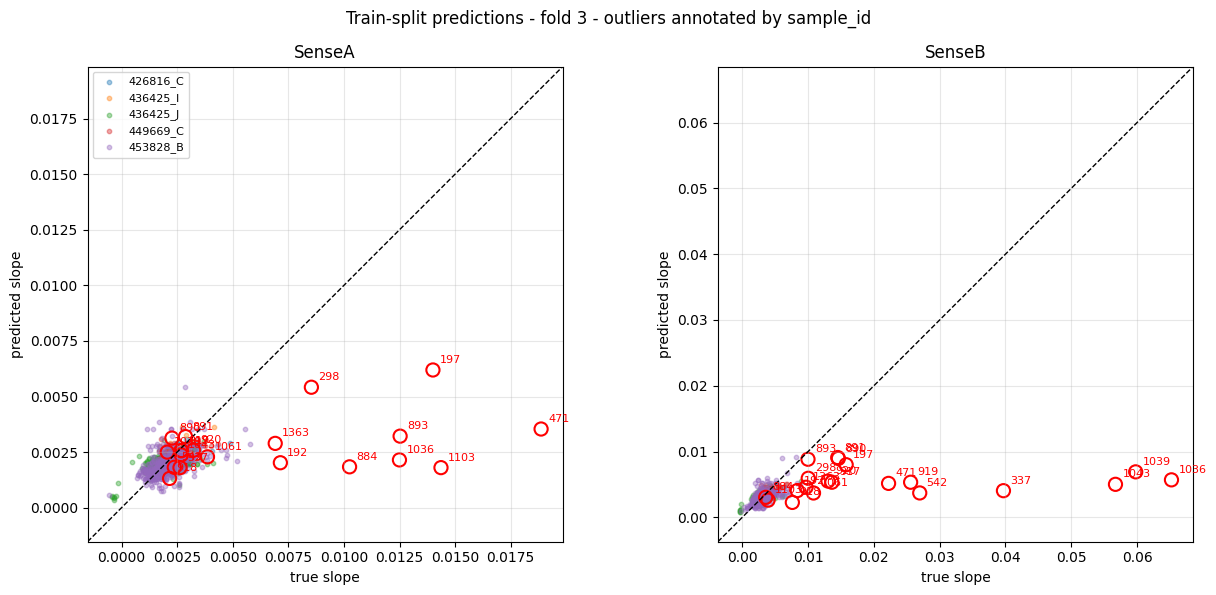

In [23]:
designs_sorted = sorted(desc["design"].unique())
cmap = plt.get_cmap("tab10")
dcolor = {d: cmap(j % 10) for j, d in enumerate(designs_sorted)}
is_out = desc["outlier"].to_numpy()

fig, axes = plt.subplots(1, 2, figsize=(13, 6))
for i, (ax, lab) in enumerate(zip(axes, ["SenseA", "SenseB"])):
    x, y = y_true[:, i], mu_y[:, i]
    for d in designs_sorted:
        m = (desc["design"] == d).to_numpy() & ~is_out
        ax.scatter(x[m], y[m], s=10, color=dcolor[d], alpha=0.4,
                   label=design_name[d])
    ax.scatter(x[is_out], y[is_out], s=90, facecolors="none",
               edgecolors="red", lw=1.5)
    for pos in outlier_pos:
        ax.annotate(str(int(desc.loc[pos, "sample_id"])),
                    (x[pos], y[pos]), textcoords="offset points",
                    xytext=(5, 5), fontsize=8, color="red")
    lims = [min(x.min(), y.min()), max(x.max(), y.max())]
    pad = 0.05 * (lims[1] - lims[0])
    lims = [lims[0] - pad, lims[1] + pad]
    ax.plot(lims, lims, "k--", lw=1)
    ax.set_xlim(lims)
    ax.set_ylim(lims)
    ax.set_aspect("equal")
    ax.set_xlabel("true slope")
    ax.set_ylabel("predicted slope")
    ax.set_title(lab)
    ax.grid(True, alpha=0.3)
axes[0].legend(fontsize=8, loc="upper left")
fig.suptitle(f"Train-split predictions - fold {FOLD} - outliers annotated by sample_id")
fig.tight_layout()
plt.show()

## 11. Summary

Interpretation guide:
- If most outliers are **in spec** on all aggregate descriptors (sections 3-5), have
  standard chain structures (6), in-range per-position values (7), normal timing (8)
  and no missing values at normally populated positions (9), then the features do not
  distinguish them from well-fitted samples: the extreme slopes are driven by
  unobserved factors (or noisy slope labels).
- Any out-of-spec finding localizes the anomaly to a specific parameter, step or
  transition and is a candidate explanation for the model's behavior (extrapolation
  regime).